# Olist EDA


In [12]:
%load_ext autoreload
%autoreload 2

In [ ]:
import pandas as pd
import numpy
from pathlib import Path

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import average_precision_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split

from delivery_delay import preprocessing, feature


from xgboost import XGBClassifier


In [15]:
SEED = 14


In [28]:


data = preprocessing.load_raw_data()
data_with_features = feature.build_features(data)
data_baseline = feature.build_dataset_baseline(data_with_features)


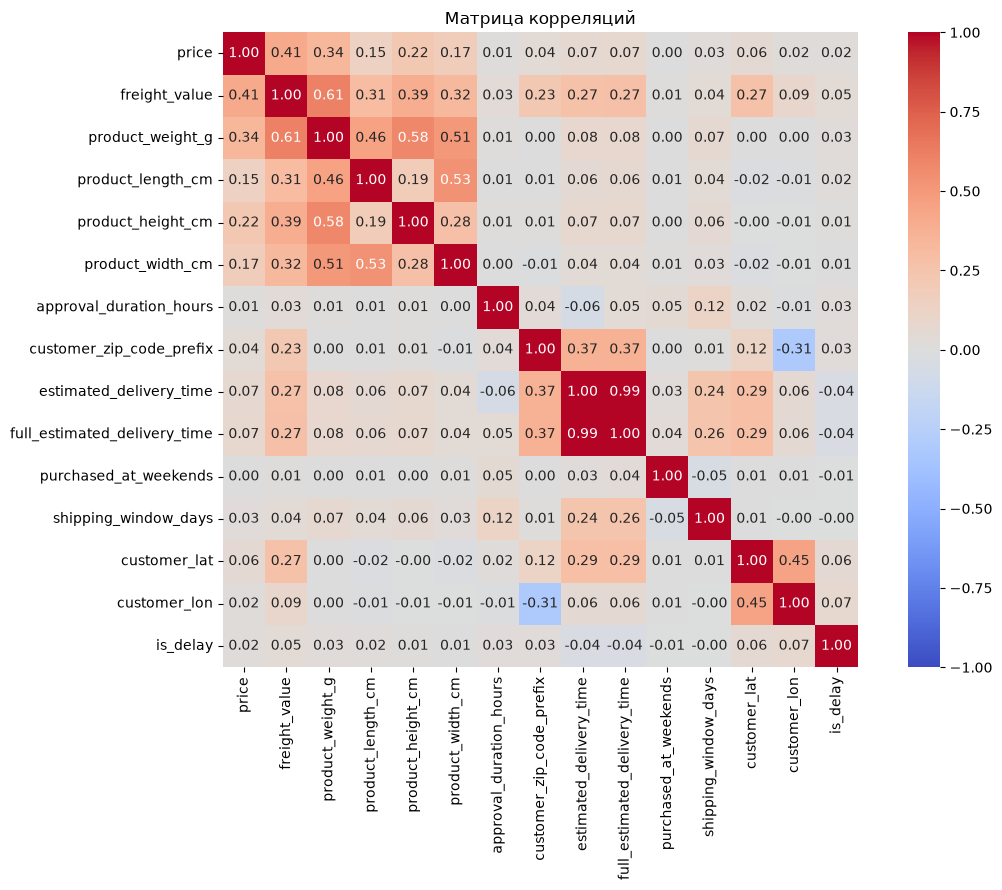

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

corr_matrix = data_baseline.corr(numeric_only=True)

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
)

plt.title("Матрица корреляций")
plt.tight_layout()
plt.show()

In [30]:
X = data_baseline.drop([ "is_delay", "order_id"], axis = 1)
y = data_baseline["is_delay"]



In [32]:
X_train, X_other, y_train, y_other = train_test_split(X, y, test_size=0.4, random_state= SEED)
X_val, X_test, y_val, y_test = train_test_split(X_other, y_other, test_size=0.5, random_state= SEED)

In [ ]:

cat_cols = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", sparse_output=True),
            cat_cols,
        )
    ],
    remainder="passthrough",
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_val_encoded = preprocessor.transform(X_val)
X_test_encoded = preprocessor.transform(X_test)

print(X_train_encoded.shape)
print(X_val_encoded.shape)

(67590, 115)
(22530, 115)


In [35]:

def clf_metrics(y_true, y_pred):
    print(f"Precision: {precision_score(y_true, y_pred, zero_division=0):.3f}")
    print(f"Recall:    {recall_score(y_true, y_pred, zero_division=0):.3f}")
    print(f"F1:        {f1_score(y_true, y_pred, zero_division=0):.3f}")


def clf_metrics_scores(y_true, scores):
    print(f"AP:        {average_precision_score(y_true, scores):.3f}")
    print(f"ROC-AUC:   {roc_auc_score(y_true, scores):.3f}")
    


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import RidgeClassifier
baseline = DummyClassifier(strategy="constant", constant=1)

baseline.fit(X_train, y_train)
dummy_pred = baseline.predict(X_val)

lr = RidgeClassifier(class_weight="balanced")


lr.fit(X_train_encoded, y_train)

import numpy as np
from sklearn.metrics import confusion_matrix

y_pred = lr.predict(X_val_encoded)
labels, counts = np.unique(y_pred, return_counts=True)


print("Confusion matrix:")

print(confusion_matrix(y_val, y_pred, labels=[0, 1]))
print(precision_score(y_val, dummy_pred))
print(precision_score(y_val, y_pred))


Confusion matrix:
[[12488  7794]
 [  584   806]]
0.06413805832410484
0.09372093023255813


In [242]:
from sklearn.ensemble import RandomForestClassifier

RFC = RandomForestClassifier( random_state=42,
    n_jobs=-1,)

RFC.fit(X_train_encoded, y_train)

y_pred = RFC.predict(X_val_encoded)

print("Confusion matrix:")

print(confusion_matrix(y_val, y_pred, labels=[0, 1]))
print(precision_score(y_val, y_pred))
print(recall_score(y_val, y_pred))
print(f1_score(y_val, y_pred))
print(roc_auc_score(y_val, y_pred))


Confusion matrix:
[[20280     2]
 [ 1234   156]]
0.9873417721518988
0.11223021582733812
0.20155038759689922
0.5560658031113813


In [26]:
#best

xgb_cls = XGBClassifier(
    objective="binary:logistic",
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=4,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="aucpr",
    early_stopping_rounds=50,
    random_state=42,
    n_jobs=-1,

)

In [36]:


xgb_cls = XGBClassifier(
    objective="binary:logistic",
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=5,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="aucpr",
    early_stopping_rounds=50,
    random_state=42,
    n_jobs=-1,
    reg_lambda=1,
)

xgb_cls.fit(
    X_train_encoded,
    y_train,
    eval_set=[(X_val_encoded, y_val)],
    verbose=100,
)

[0]	validation_0-aucpr:0.12011
[100]	validation_0-aucpr:0.16848
[200]	validation_0-aucpr:0.18276
[300]	validation_0-aucpr:0.19304
[400]	validation_0-aucpr:0.19907
[500]	validation_0-aucpr:0.20459
[600]	validation_0-aucpr:0.21035
[700]	validation_0-aucpr:0.21506
[800]	validation_0-aucpr:0.21975
[900]	validation_0-aucpr:0.22448
[999]	validation_0-aucpr:0.22919


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",50
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'aucpr'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


TRAIN
Precision: 0.990
Recall:    0.110
F1:        0.198
AP:        0.663
ROC-AUC:   0.939
VALIDATION
Confusion matrix:
[[21080    13]
 [ 1393    44]]
Precision: 0.772
Recall:    0.031
F1:        0.059
AP:        0.230
ROC-AUC:   0.761


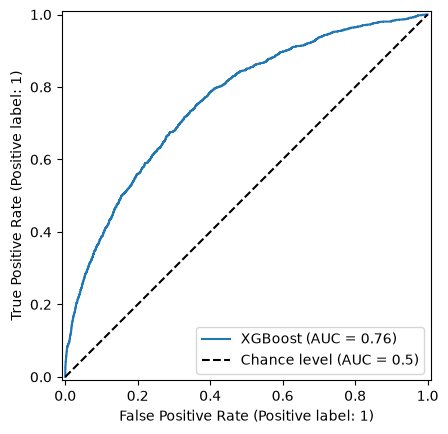

In [37]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    RocCurveDisplay
    

)

scores = xgb_cls.predict_proba(X_val_encoded)[:, 1]
scores_train = xgb_cls.predict_proba(X_train_encoded)[:,1]
threshold = 0.5
predictions = (scores >= threshold).astype(int)
predictions_train = (scores_train >= threshold).astype(int)


RocCurveDisplay.from_predictions(
    y_val,
    scores,
    name="XGBoost",
    plot_chance_level=True,
)

print("TRAIN")

clf_metrics(y_train, predictions_train)
clf_metrics_scores(y_train, scores_train)
print("VALIDATION")
print("Confusion matrix:")
print(confusion_matrix(y_val, predictions, labels=[0, 1]))
clf_metrics(y_val, predictions)
clf_metrics_scores(y_val, scores)
# print(f"Best round: {xgb_cls.best_iteration + 1}")



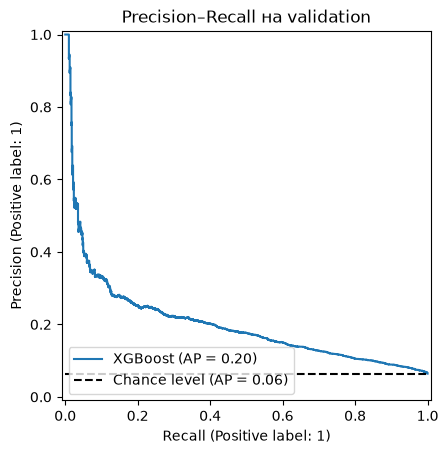

In [254]:
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay

scores_val = xgb_cls.predict_proba(X_val_encoded)[:, 1]

PrecisionRecallDisplay.from_predictions(
    y_val,
    scores_val,
    name="XGBoost",
    plot_chance_level=True,
)

plt.title("Precision–Recall на validation")
plt.show()

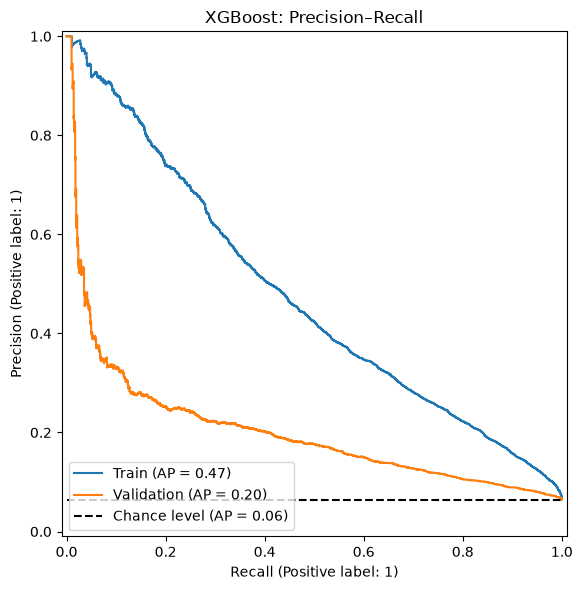

In [255]:
scores_train = xgb_cls.predict_proba(X_train_encoded)[:, 1]
scores_val = xgb_cls.predict_proba(X_val_encoded)[:, 1]

fig, ax = plt.subplots(figsize=(8, 6))

PrecisionRecallDisplay.from_predictions(
    y_train,
    scores_train,
    name="Train",
    ax=ax,
)

PrecisionRecallDisplay.from_predictions(
    y_val,
    scores_val,
    name="Validation",
    ax=ax,
    plot_chance_level=True,
)

ax.set_title("XGBoost: Precision–Recall")
plt.tight_layout()
plt.show()

## regression experiments 

In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import root_mean_squared_error

from sklearn.linear_model import LinearRegression
baseline = DummyRegressor(strategy="mean")
lr = LinearRegression()
lr.fit(X_train_encoded, y_train)

baseline.fit(X_train, y_train)

lr_pred = lr.predict(X_val_encoded)
dummy_pred = baseline.predict(X_val)
dummy_mae = mean_absolute_error(y_val, dummy_pred)
dummy_rmse = root_mean_squared_error(y_val, dummy_pred)

lr_mae = mean_absolute_error(y_val, lr_pred)
lr_rmse = root_mean_squared_error(y_val, lr_pred)

print(f"Predicted delay for every order: {baseline.constant_.item():.2f} days")
print(f" dummy MAE: {dummy_mae:.2f} | lr MAE{lr_mae:.2f}")
print(f" dummy RMSE: {dummy_rmse:.2f} | lr RMSE {lr_rmse:.2f} ")

Predicted delay for every order: 0.07 days
 dummy MAE: 0.12 | lr MAE0.12
 dummy RMSE: 0.25 | lr RMSE 0.24 


In [23]:
from xgboost import XGBRegressor
# from xgboost import Rand
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

xgb = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="rmse",
    early_stopping_rounds=50,
    random_state=42,
    n_jobs=-1,
)

xgb.fit(
    X_train_encoded,
    y_train,
    eval_set=[(X_val_encoded, y_val)],
    verbose=100,
)

[0]	validation_0-rmse:4.69291
[69]	validation_0-rmse:4.69793


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",50
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'rmse'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [24]:
train_predictions = xgb.predict(X_train_encoded)
val_predictions = xgb.predict(X_val_encoded)

for name, actual, predicted in [
    ("Train", y_train, train_predictions),
    ("Validation", y_val, val_predictions),
]:
    mae = mean_absolute_error(actual, predicted)
    rmse = root_mean_squared_error(actual, predicted)

    print(f"{name}: MAE {mae:.2f} | RMSE {rmse:.2f}")

print(f"Best boosting round: {xgb.best_iteration + 1}")

Train: MAE 1.25 | RMSE 4.38
Validation: MAE 1.28 | RMSE 4.68
Best boosting round: 20


In [25]:
print("Original features:")
print(X_train.columns.tolist())

print("\nEncoded shape:")
print(X_train_encoded.shape)

print("\nTraining target distribution:")
print(y_train.describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

Original features:
['price', 'freight_value', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'approval_duration_hours', 'product_category_name', 'customer_state']

Encoded shape:
(65185, 107)

Training target distribution:
count    65185.000000
mean         0.680755
std          4.481057
min          0.000000
50%          0.000000
90%          0.000000
95%          3.000000
99%         18.000000
max        181.000000
Name: overdue_days, dtype: float64


In [28]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=10,
    max_features=0.8,
    criterion="squared_error",
    random_state=42,
    n_jobs=-1,
)

rf.fit(X_train_encoded, y_train)

train_predictions = rf.predict(X_train_encoded)
val_predictions = rf.predict(X_val_encoded)

for name, actual, predicted in [
    ("Train", y_train, train_predictions),
    ("Validation", y_val, val_predictions),
]:
    mae = mean_absolute_error(actual, predicted)
    rmse = root_mean_squared_error(actual, predicted)
    

    print(f"{name}: MAE {mae:.2f} | RMSE {rmse:.2f}")

Train: MAE 1.19 | RMSE 4.24
Validation: MAE 1.27 | RMSE 4.67


In [99]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

xgb_rf = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=1,          # One boosting round
    num_parallel_tree=300,  # 300 trees in that round
    learning_rate=1.0,
    max_depth=8,
    subsample=0.8,
    colsample_bynode=0.8,
    tree_method="hist",
    random_state=42,
    n_jobs=-1,
)

xgb_rf.fit(X_train_encoded, y_train)

for name, X_part, y_part in [
    ("Train", X_train_encoded, y_train),
    ("Validation", X_val_encoded, y_val),
]:
    predictions = xgb_rf.predict(X_part)

    mae = mean_absolute_error(y_part, predictions)
    rmse = root_mean_squared_error(y_part, predictions)

    print(f"{name}: MAE {mae:.2f} | RMSE {rmse:.2f}")

Train: MAE 1.18 | RMSE 4.04
Validation: MAE 1.25 | RMSE 4.70
